# Menschen und Objekte auf Bildern erkennen

Ein Bild laden, mit **DETR ResNet-50** auswerten und Personen sowie weitere
Objektklassen markieren, etwa Autos, Fahrräder, Busse, Tiere oder Möbel.
Kein CARLA-Server nötig. Standardmäßig werden alle vom Modell unterstützten
Klassen angezeigt. In Abschnitt 6 kannst du die Auswahl einschränken.

**Bedienung:** Zelle anklicken und **Shift+Enter** drücken. Von oben nach unten
arbeiten. `[*]` links bedeutet, dass die Zelle noch rechnet. Ergebnisse erscheinen
unter der Zelle. Nach einem Bildwechsel Abschnitte **4 → 5 → 6** erneut ausführen.

Das Modell kennt eine feste Menge von Objektklassen. Es erkennt nicht automatisch
alles Unbekannte. Die Scores sind Detektorkonfidenzen, keine Probly-Unsicherheit.


## 1. Python und Rechengerät prüfen
Wir beginnen auf der CPU, damit der erste Versuch möglichst einfach läuft.
Später kannst du `DEVICE = "mps"` für die Apple-GPU ausprobieren. Falls dann ein
Fehler auftritt, wieder `"cpu"` wählen und ab Zelle 2 erneut ausführen.


In [1]:
import os
import sys
from pathlib import Path
from datetime import datetime
import json
import time
import torch
from PIL import Image, ImageDraw, ImageOps, ImageFont
from collections import Counter
from IPython.display import display
from transformers import AutoImageProcessor, AutoModelForObjectDetection

ROOT = Path.cwd()
BILDER = ROOT / "bilder"
ERGEBNISSE = ROOT / "ergebnisse"
BILDER.mkdir(exist_ok=True)
ERGEBNISSE.mkdir(exist_ok=True)
os.environ.setdefault("HF_HOME", str(ROOT / "model_cache"))
DEVICE = "cpu"
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Apple-GPU verfügbar:", torch.backends.mps.is_available())
print("Bilderordner:", BILDER.resolve())


Python: 3.12.14
PyTorch: 2.7.1
Apple-GPU verfügbar: True
Bilderordner: /Users/robelteleale/Documents/Codex/2026-10-30/ich/outputs/Personenerkennung_Mac/bilder


## 2. Modell laden
`facebook/detr-resnet-50` ist bereits für viele COCO-Objektklassen trainiert.
Bisher wurde die Ausgabe auf `person` beschränkt. Jetzt können alle unterstützten
Klassen angezeigt werden; dafür ist kein neues Training erforderlich.

Der erste Lauf lädt bei Bedarf die Modellgewichte. Danach wird der Cache verwendet.
Für dieses öffentliche Modell brauchst du keinen Token.


In [2]:
MODEL_ID = "facebook/detr-resnet-50"
processor = AutoImageProcessor.from_pretrained(MODEL_ID, use_fast=False)
model = AutoModelForObjectDetection.from_pretrained(
    MODEL_ID, use_safetensors=True, use_pretrained_backbone=False
).to(DEVICE).eval()
print("Modell bereit:", MODEL_ID, "auf", DEVICE)

verfuegbare_klassen = sorted({name for name in model.config.id2label.values() if name != "N/A"})
print("Unterstützte Klassen:", ", ".join(verfuegbare_klassen))


Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Modell bereit: facebook/detr-resnet-50 auf cpu
Unterstützte Klassen: airplane, apple, backpack, banana, baseball bat, baseball glove, bear, bed, bench, bicycle, bird, blender, boat, book, bottle, bowl, broccoli, bus, cake, car, carrot, cat, cell phone, chair, clock, couch, cow, cup, desk, dining table, dog, donut, door, elephant, eye glasses, fire hydrant, fork, frisbee, giraffe, hair drier, handbag, hat, horse, hot dog, keyboard, kite, knife, laptop, microwave, mirror, motorcycle, mouse, orange, oven, parking meter, person, pizza, plate, potted plant, refrigerator, remote, sandwich, scissors, sheep, shoe, sink, skateboard, skis, snowboard, spoon, sports ball, stop sign, street sign, suitcase, surfboard, teddy bear, tennis racket, tie, toaster, toilet, toothbrush, traffic light, train, truck, tv, umbrella, vase, window, wine glass, zebra


## 3. Eigenes Bild auswählen
Lege JPG-, PNG- oder WebP-Dateien in den Ordner **bilder**. In PyCharm kannst du sie
links in den Projektordner ziehen. Führe danach die folgende Zelle erneut aus,
um die nummerierte Liste zu aktualisieren.

Für den Anfang eignet sich ein scharfes Bild mit gut sichtbaren Menschen und
Fahrzeugen. Die Erkennung erfolgt lokal auf deinem Mac.


In [3]:
bild_dateien = sorted(p for p in BILDER.iterdir()
                       if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
for index, path in enumerate(bild_dateien):
    print(index, path.name)
if not bild_dateien:
    print("Noch kein Bild vorhanden. Bitte ein Bild in den Ordner bilder hochladen und diese Zelle erneut ausführen.")


0 0.jpg
1 1.jpg
2 2.jpeg
3 3.jpg
4 4.png
5 5.png
6 6.png
7 7.png


## 4. Bild anzeigen
Bei mehreren Bildern `BILD_NUMMER` ändern: 0 ist das erste, 1 das zweite usw.
Nach einem Bildwechsel diese und die folgenden Zellen erneut ausführen.


7.png (1536, 1024)


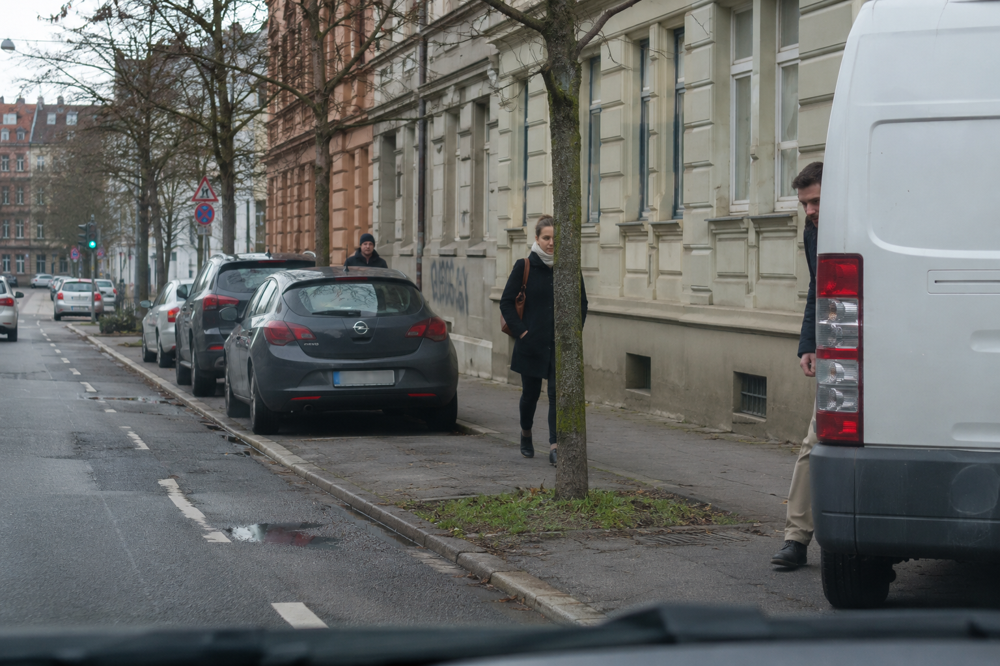

In [30]:
BILD_NUMMER = 7
if not bild_dateien:
    raise ValueError("Zuerst ein Bild in bilder legen und Zelle 3 erneut ausführen.")
if not 0 <= BILD_NUMMER < len(bild_dateien):
    raise ValueError("BILD_NUMMER liegt außerhalb der angezeigten Liste.")
# Clear old results so they cannot be drawn on a different image.
alle_ergebnisse = None
markiert = None
auswertung = None
BILD_PFAD = bild_dateien[BILD_NUMMER]
with Image.open(BILD_PFAD) as opened:
    bild = ImageOps.exif_transpose(opened).convert("RGB")
# Limit very large phone photos for a comfortable display and a smaller first test.
bild.thumbnail((1600, 1200))
print(BILD_PFAD.name, bild.size)
display(bild)


## 5. Modell ausführen
Diese Zelle berechnet alle Objektergebnisse einmal. Beim ersten Durchlauf kann es
etwas länger dauern. Die Laufzeit ist nur ein grober Hinweis, kein Benchmark.


In [31]:
markiert = None
auswertung = None
inputs = processor(images=bild, return_tensors="pt").to(DEVICE)
start = time.perf_counter()
with torch.inference_mode():
    outputs = model(**inputs)
if DEVICE == "mps":
    torch.mps.synchronize()
print(f"Modelldurchlauf: {time.perf_counter() - start:.2f} Sekunden")
target_sizes = torch.tensor([[bild.height, bild.width]], device=DEVICE)
raw_result = processor.post_process_object_detection(
    outputs, target_sizes=target_sizes, threshold=0.0
)[0]
alle_ergebnisse = [
    {"klasse": model.config.id2label[int(label.item())],
     "score": float(score.item()),
     "box": [float(v) for v in box.detach().cpu().tolist()]}
    for label, score, box in zip(raw_result["labels"], raw_result["scores"], raw_result["boxes"])
]

print("Analysiertes Bild:", BILD_PFAD.name)


Modelldurchlauf: 1.66 Sekunden
Analysiertes Bild: 7.png


## 6. Objektklassen auswählen, markieren und zählen

- **`KLASSEN = None`**: alle vom Modell unterstützten Klassen anzeigen.
- **`KLASSEN = ["person", "car", "bicycle", "bus", "truck", "motorcycle"]`**:
  nur diese Verkehrsteilnehmer anzeigen.
- **`KLASSEN = ["person"]`**: nur Menschen anzeigen, wie bisher.

Verwende die englischen Namen aus der Ausgabe von Abschnitt 2. Jede Klasse bekommt
eine eigene Farbe und wird separat gezählt. `SCHWELLE` filtert die Detektorscores.
Probiere zum Beispiel 0.3, 0.5 und 0.9 auf demselben Bild aus. Dazu nur diese Zelle
erneut ausführen. Deine bisher eingestellte Schwelle wurde übernommen.

Eine kleinere Schwelle kann mehr echte Objekte, aber auch mehr falsche Meldungen
zeigen. Ein Score von 0.9 ist keine Garantie für eine richtige Erkennung.


Bild: 7.png | Schwelle: 0.5 | Erkannte Objekte: 4
  person: 4


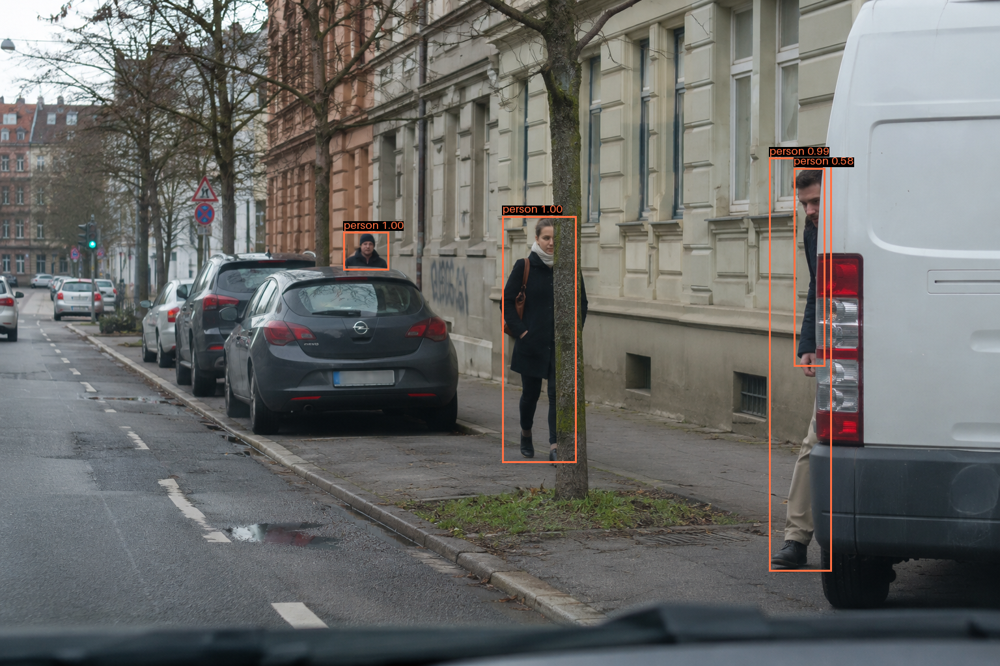

In [34]:
# Load these here too, so this cell also works in an existing notebook session.
from collections import Counter
from PIL import ImageFont
verfuegbare_klassen = sorted({name for name in model.config.id2label.values() if name != "N/A"})

SCHWELLE = 0.5
KLASSEN = ["person"] # All supported classes; alternatively use ["person", "car", "bus"].

if not 0 <= SCHWELLE <= 1:
    raise ValueError("SCHWELLE muss zwischen 0 und 1 liegen.")
if alle_ergebnisse is None:
    raise ValueError("Das Bild wurde gewechselt. Bitte zuerst Abschnitt 5 ausführen.")
if KLASSEN is not None:
    if not isinstance(KLASSEN, (list, tuple, set)):
        raise ValueError('KLASSEN muss None oder eine Liste wie ["person", "car"] sein.')
    unbekannte_namen = set(KLASSEN) - set(verfuegbare_klassen)
    if unbekannte_namen:
        raise ValueError(f"Nicht unterstützte Klassennamen: {sorted(unbekannte_namen)}. Siehe Abschnitt 2.")

objekte = [r for r in alle_ergebnisse
           if r["klasse"] != "N/A" and r["score"] >= SCHWELLE
           and (KLASSEN is None or r["klasse"] in KLASSEN)]
anzahl_pro_klasse = dict(sorted(Counter(r["klasse"] for r in objekte).items()))
palette = ["#00FF66", "#00BFFF", "#FFB000", "#FF66CC", "#B699FF",
           "#FF7043", "#33FFFF", "#CCFF00", "#FF6666", "#FFFFFF"]
farben = {klasse: palette[index % len(palette)]
          for index, klasse in enumerate(verfuegbare_klassen)}
markiert = bild.copy()
zeichnen = ImageDraw.Draw(markiert)
schrift = ImageFont.load_default(size=max(14, round(bild.width / 90)))
for objekt in objekte:
    x1, y1, x2, y2 = objekt["box"]
    farbe = farben[objekt["klasse"]]
    zeichnen.rectangle((x1, y1, x2, y2), outline=farbe, width=3)
    beschriftung = f"{objekt['klasse']} {objekt['score']:.2f}"
    text_x = max(0, x1)
    text_y = max(0, y1 - 22)
    hintergrund = zeichnen.textbbox((text_x, text_y), beschriftung, font=schrift)
    zeichnen.rectangle(hintergrund, fill="black")
    zeichnen.text((text_x, text_y), beschriftung, font=schrift, fill=farbe)

auswertung = {
    "bild": BILD_PFAD.name, "bildgroesse": list(bild.size),
    "modell": MODEL_ID, "schwelle": SCHWELLE,
    "klassenfilter": sorted(KLASSEN) if KLASSEN is not None else None,
    "anzahl_pro_klasse": anzahl_pro_klasse, "objekte": objekte,
}
print(f"Bild: {BILD_PFAD.name} | Schwelle: {SCHWELLE} | Erkannte Objekte: {len(objekte)}")
for klasse, anzahl in anzahl_pro_klasse.items():
    print(f"  {klasse}: {anzahl}")
if not objekte:
    print("Keine passenden Erkennungen. Prüfe die Klassenauswahl und die Schwelle.")
display(markiert)


## 7. Ergebnis speichern
Speichert das markierte Bild und eine JSON-Datei mit Objektklassen, Scores,
Kästchen, Klassenfilter und Anzahl je Klasse. Die Koordinaten beziehen sich auf
das angezeigte, gegebenenfalls verkleinerte Bild. Frühere Dateien bleiben erhalten.

Nach einem Bildwechsel oder neuer Analyse zuerst Abschnitt 6 erneut ausführen.


In [32]:
if markiert is None or auswertung is None:
    raise ValueError("Bitte zuerst Abschnitt 6 ausführen, um das aktuelle Ergebnis zu erstellen.")
name = BILD_PFAD.stem + "_objekte_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
markiert.save(ERGEBNISSE / f"{name}_erkannt.png")
(ERGEBNISSE / f"{name}.json").write_text(
    json.dumps(auswertung, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Gespeichert in:", ERGEBNISSE.resolve())


Gespeichert in: /Users/robelteleale/Documents/Codex/2026-10-30/ich/outputs/Personenerkennung_Mac/ergebnisse


## Was du jetzt untersuchen kannst

- Zähle selbst sichtbare Menschen und andere Objekte und vergleiche sie mit den Kästchen.
- Welche Menschen oder Objekte übersieht das Modell: kleine, verdeckte oder unscharfe?
- Was ändert sich bei verschiedenen Schwellen auf demselben Bild?
- Gibt es falsche Klassen oder Kästchen um nicht vorhandene Objekte?

Ohne eigene Referenzbeschriftung berechnet dieses Notebook noch keine belastbare
Erkennungsrate. Notiere deine Beobachtungen für das Gruppentreffen.

**Jupyter-Grundlagen:** Bleistiftsymbol/Editor: Code bearbeiten; Shift+Enter:
ausführen; Quadrat oben: laufende Berechnung unterbrechen. Über **Kernel → Restart
Kernel** löschst du alle Python-Variablen; danach wieder von oben anfangen. Mit
Cmd+S das Notebook speichern. Ein Notebook enthält Code, Texte und gespeicherte
Ausgaben, aber nicht die Modellgewichte oder deine Bilder.

**Anderes Modell:** Der Name in Zelle 2 kann später gegen einen kompatiblen
Objektdetektor wie `facebook/detr-resnet-101` getauscht werden. Dann ab Zelle 2 neu
ausführen. Ein Segmentierungs- oder Tiefenmodell benötigt einen anderen Auswertungscode.

Quellen: [DETR-Modell](https://huggingface.co/facebook/detr-resnet-50),
[PyTorch auf macOS](https://pytorch.org/get-started/locally/).
